In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

In [2]:
df = pd.read_csv('../data/processed/cleaned_data.csv')

print("Cleaned data loaded")
print("Shape:", df.shape)

Cleaned data loaded
Shape: (938599, 41)


C:\Users\surek\AppData\Local\Temp\ipykernel_1980\1394678090.py:1: DtypeWarning: Columns (3: pdes) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('../data/processed/cleaned_data.csv')


In [3]:
# Numeric vs Categorical Columns

numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()

print("Numeric columns:", len(numeric_cols))
print("Categorical columns:", len(categorical_cols))

Numeric columns: 33
Categorical columns: 8


C:\Users\surek\AppData\Local\Temp\ipykernel_1980\4201069444.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include=['object']).columns.tolist()


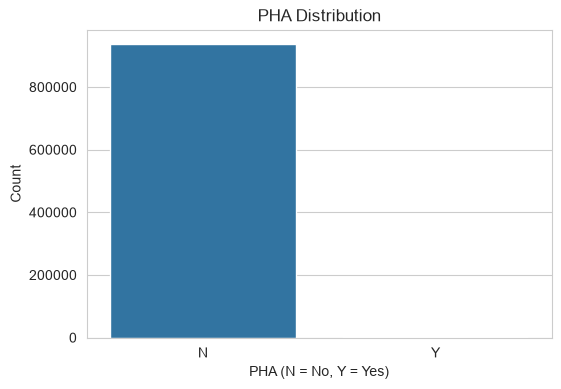

PHA value counts:
pha
N    936533
Y      2066
Name: count, dtype: int64


In [4]:
#Target Distribution — PHA


plt.figure(figsize=(6, 4))
sns.countplot(x='pha', data=df)
plt.title('PHA Distribution')
plt.xlabel('PHA (N = No, Y = Yes)')
plt.ylabel('Count')
plt.show()

print("PHA value counts:")
print(df['pha'].value_counts())

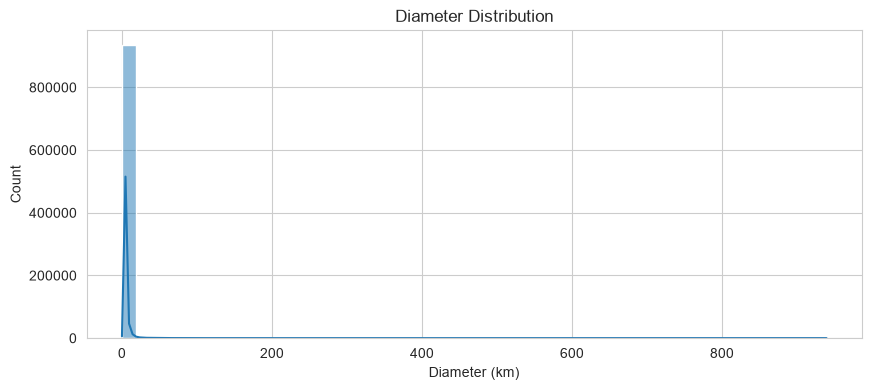

Diameter statistics:
count    938599.000000
mean          4.194676
std           3.630911
min           0.002500
25%           3.972000
50%           3.972000
75%           3.972000
max         939.400000
Name: diameter, dtype: float64


In [5]:
#Target Distribution — Diameter

plt.figure(figsize=(10, 4))
sns.histplot(df['diameter'], bins=50, kde=True)
plt.title('Diameter Distribution')
plt.xlabel('Diameter (km)')
plt.show()

print("Diameter statistics:")
print(df['diameter'].describe())

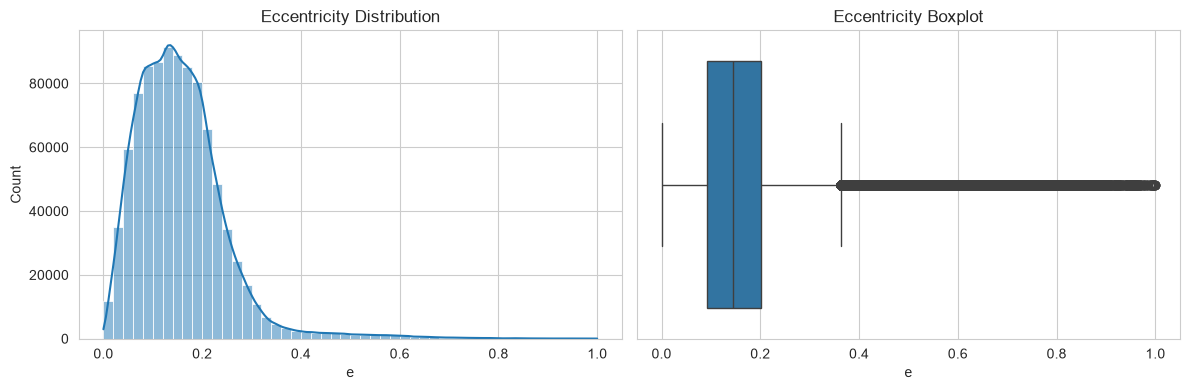

In [6]:
#Univariate — Eccentricity

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df['e'], bins=50, kde=True, ax=axes[0])
axes[0].set_title('Eccentricity Distribution')

sns.boxplot(x=df['e'], ax=axes[1])
axes[1].set_title('Eccentricity Boxplot')

plt.tight_layout()
plt.show()

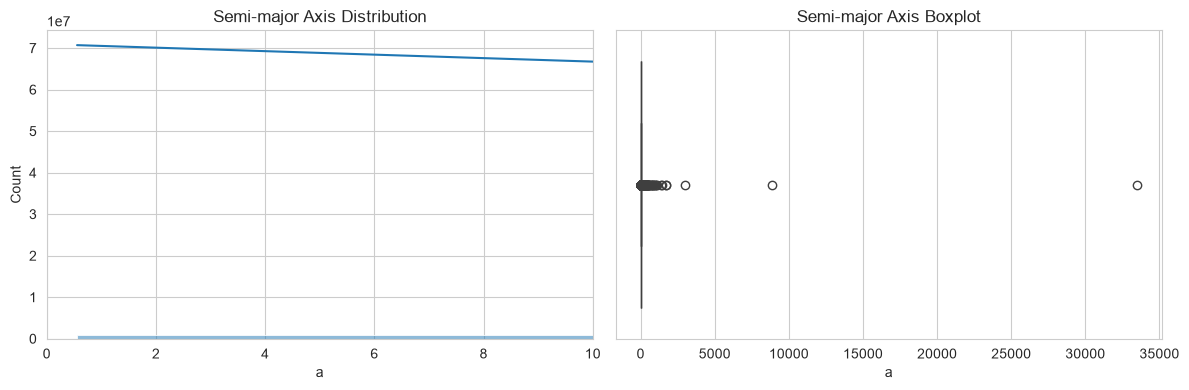

In [7]:
#Univariate — Semi-major Axis

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df['a'], bins=50, kde=True, ax=axes[0])
axes[0].set_title('Semi-major Axis Distribution')
axes[0].set_xlim(0, 10)

sns.boxplot(x=df['a'], ax=axes[1])
axes[1].set_title('Semi-major Axis Boxplot')

plt.tight_layout()
plt.show()

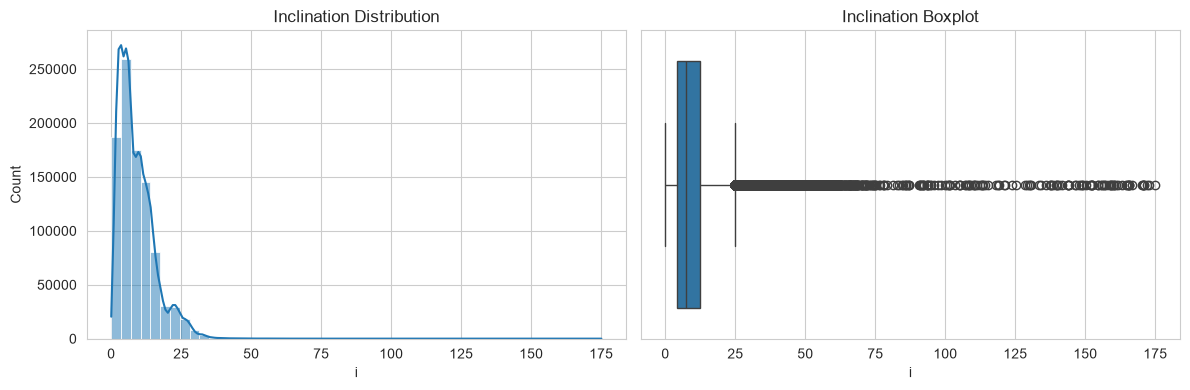

In [8]:
#Univariate — Inclination

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df['i'], bins=50, kde=True, ax=axes[0])
axes[0].set_title('Inclination Distribution')

sns.boxplot(x=df['i'], ax=axes[1])
axes[1].set_title('Inclination Boxplot')

plt.tight_layout()
plt.show()

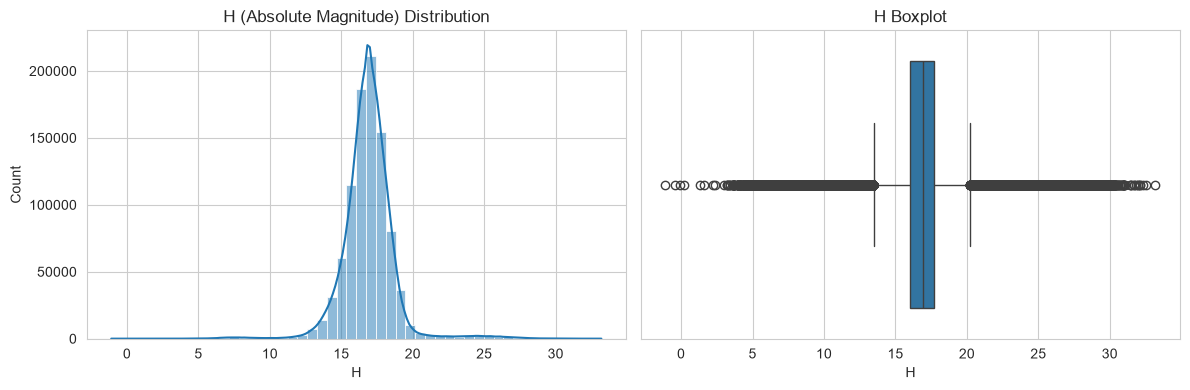

In [9]:
# Univariate — H (Absolute Magnitude)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df['H'], bins=50, kde=True, ax=axes[0])
axes[0].set_title('H (Absolute Magnitude) Distribution')

sns.boxplot(x=df['H'], ax=axes[1])
axes[1].set_title('H Boxplot')

plt.tight_layout()
plt.show()

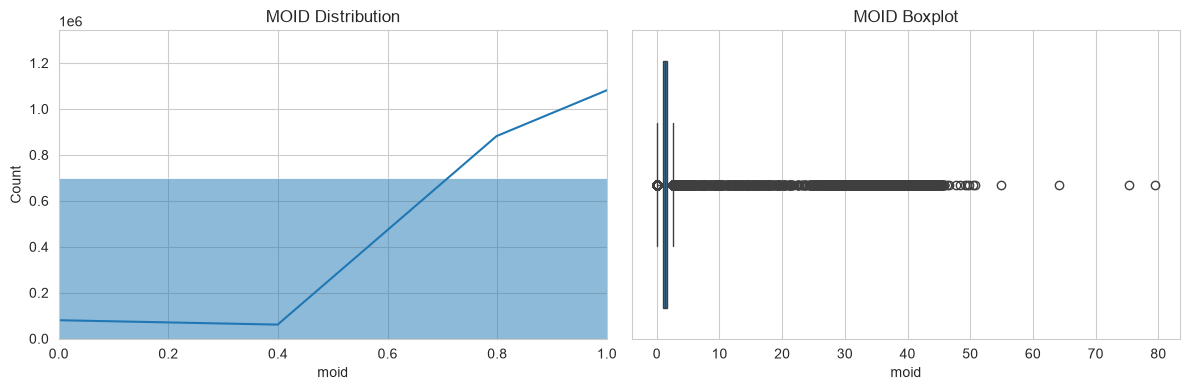

In [10]:
#Univariate — MOID

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df['moid'], bins=50, kde=True, ax=axes[0])
axes[0].set_title('MOID Distribution')
axes[0].set_xlim(0, 1)

sns.boxplot(x=df['moid'], ax=axes[1])
axes[1].set_title('MOID Boxplot')

plt.tight_layout()
plt.show()

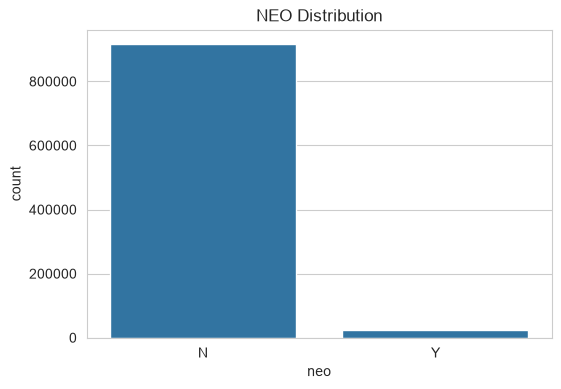

neo
N    915705
Y     22894
Name: count, dtype: int64


In [11]:
#Categorical — NEO

plt.figure(figsize=(6, 4))
sns.countplot(x='neo', data=df)
plt.title('NEO Distribution')
plt.show()

print(df['neo'].value_counts())

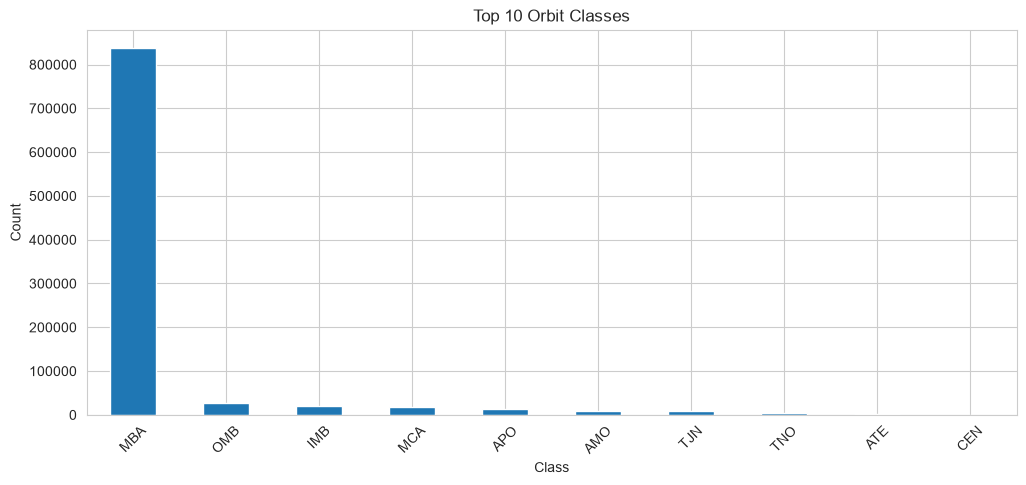

class
MBA    837430
OMB     27815
IMB     19903
MCA     18356
APO     12687
AMO      8456
TJN      8160
TNO      3462
ATE      1729
CEN       504
Name: count, dtype: int64


In [12]:
#Categorical — Class

plt.figure(figsize=(12, 5))
df['class'].value_counts().head(10).plot(kind='bar')
plt.title('Top 10 Orbit Classes')
plt.xlabel('Class')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

print(df['class'].value_counts().head(10))

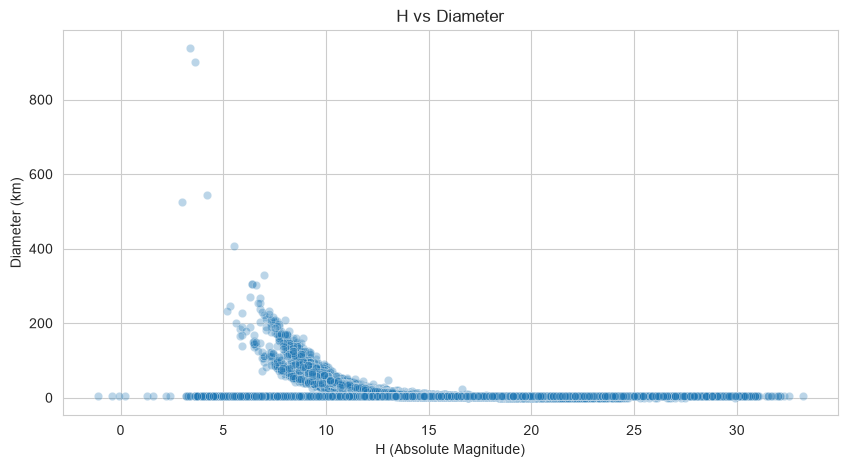

In [13]:
#Bivariate — H vs Diameter

plt.figure(figsize=(10, 5))
sns.scatterplot(x='H', y='diameter', data=df, alpha=0.3)
plt.title('H vs Diameter')
plt.xlabel('H (Absolute Magnitude)')
plt.ylabel('Diameter (km)')
plt.show()

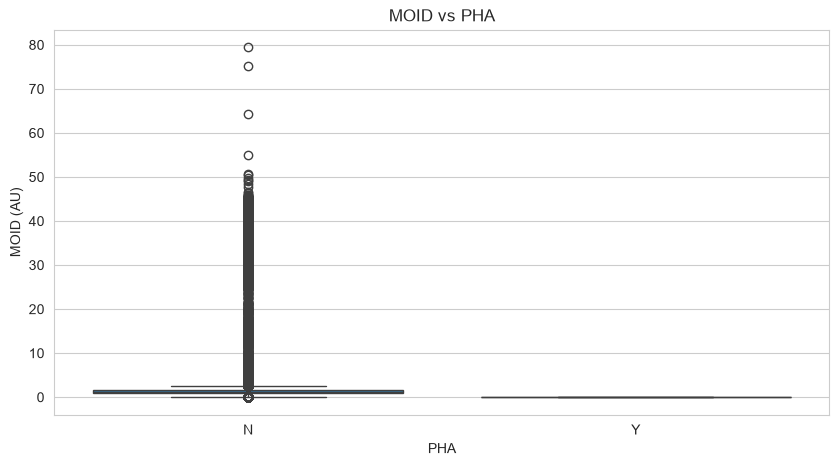

In [15]:
 #Bivariate — MOID vs PHA
plt.figure(figsize=(10, 5))
sns.boxplot(x='pha', y='moid', data=df)
plt.title('MOID vs PHA')
plt.xlabel('PHA')
plt.ylabel('MOID (AU)')
plt.show()

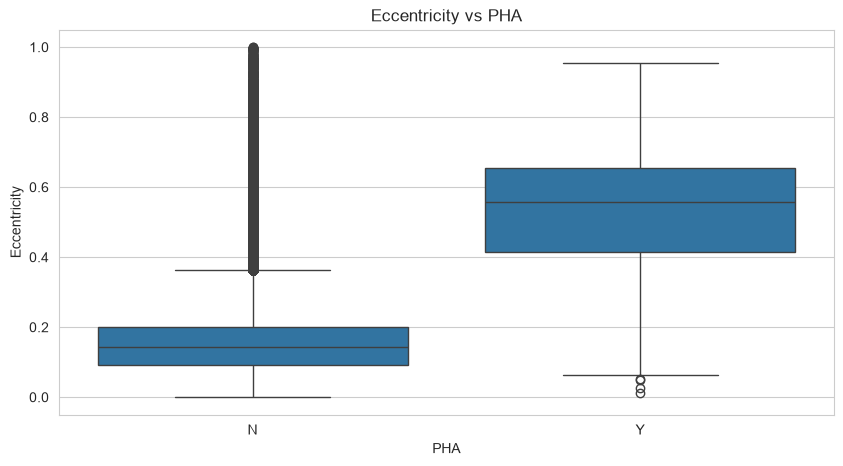

In [16]:
#Bivariate — Eccentricity vs PHA
plt.figure(figsize=(10, 5))
sns.boxplot(x='pha', y='e', data=df)
plt.title('Eccentricity vs PHA')
plt.xlabel('PHA')
plt.ylabel('Eccentricity')
plt.show()

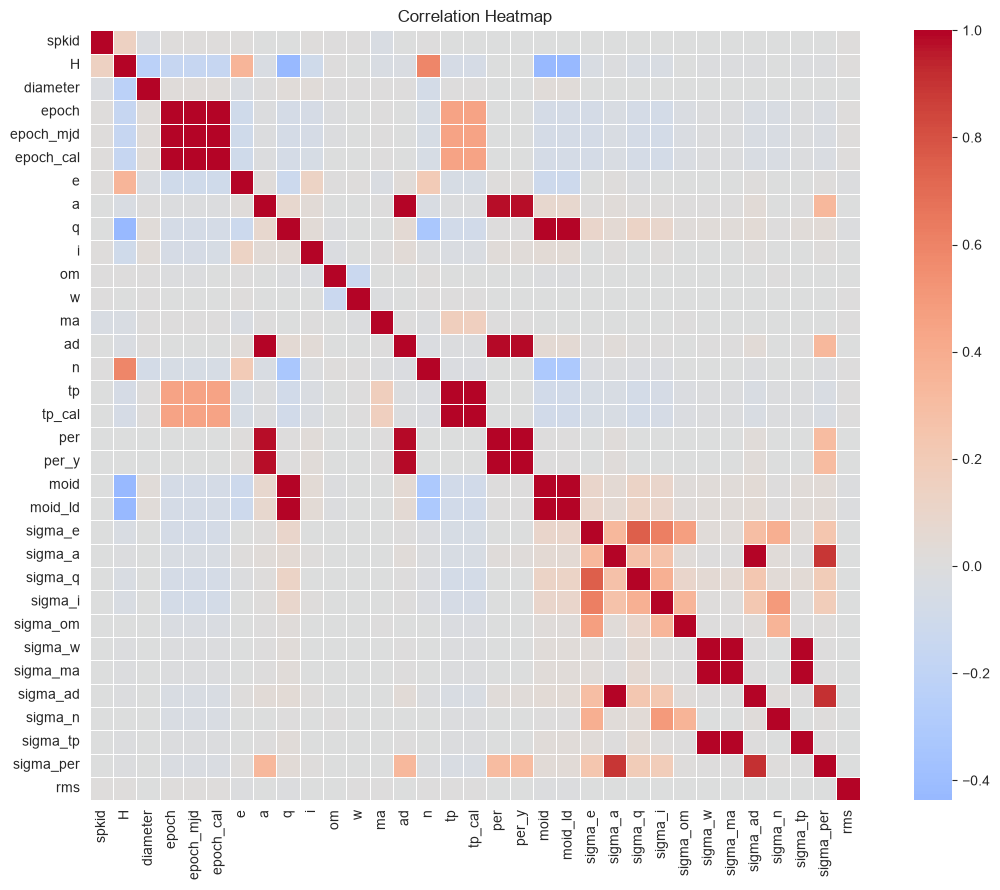

In [17]:
 #Correlation Heatmap

plt.figure(figsize=(14, 10))

corr = df[numeric_cols].corr()

sns.heatmap(corr, annot=False, cmap='coolwarm', center=0, 
            square=True, linewidths=0.5)
plt.title('Correlation Heatmap')
plt.show()

In [18]:
#Top Correlations
corr_matrix = df[numeric_cols].corr()

# Top correlations with diameter
print("Top correlations with diameter:")
print(corr_matrix['diameter'].sort_values(ascending=False).head(10))

# Top correlations with H
print("\nTop correlations with H:")
print(corr_matrix['H'].sort_values(ascending=False).head(10))

Top correlations with diameter:
diameter     1.000000
i            0.032747
moid_ld      0.029996
moid         0.029996
q            0.029928
epoch        0.021203
epoch_mjd    0.021203
epoch_cal    0.021115
tp_cal       0.004309
tp           0.004255
Name: diameter, dtype: float64

Top correlations with H:
H           1.000000
n           0.587390
e           0.346393
spkid       0.146389
rms         0.006654
om          0.001043
sigma_n     0.000125
w          -0.003250
sigma_om   -0.004484
per_y      -0.004489
Name: H, dtype: float64


In [19]:
#Skewness Check

skewness = df[numeric_cols].skew().sort_values(ascending=False)

print("Skewness of numeric columns:")
print(skewness)

Skewness of numeric columns:
rms          966.901460
sigma_tp     960.972161
sigma_ma     959.728412
sigma_w      959.726907
per_y        943.050094
per          943.050094
ad           855.461985
a            850.370851
sigma_om     793.985705
sigma_ad     660.965974
sigma_a      627.860300
sigma_n      622.866841
sigma_per    538.582284
sigma_i      264.273906
sigma_e      228.766858
sigma_q      228.560758
diameter      66.686800
moid_ld       15.755948
moid          15.755948
q             15.697661
spkid          7.089897
n              5.622871
i              2.190235
e              1.903127
H              0.628988
om             0.197438
ma             0.043715
w             -0.020549
tp_cal        -4.607654
tp            -4.648741
epoch         -6.797354
epoch_mjd     -6.797354
epoch_cal     -6.801892
dtype: float64


In [20]:
#Outlier Check (IQR Method)
def count_outliers(series):
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    return ((series < lower) | (series > upper)).sum()

outliers = {}
for col in numeric_cols:
    outliers[col] = count_outliers(df[col])

outlier_df = pd.DataFrame({
    'Outlier Count': outliers,
    'Outlier %': (pd.Series(outliers) / len(df)) * 100
}).sort_values('Outlier %', ascending=False)

print("Outliers per column:")
print(outlier_df.head(15))

Outliers per column:
           Outlier Count  Outlier %
sigma_e           200122  21.321352
sigma_q           197165  21.006308
sigma_n           191487  20.401364
sigma_ad          189300  20.168357
sigma_ma          189058  20.142574
sigma_a           188582  20.091860
sigma_per         188230  20.054358
sigma_tp          186572  19.877711
sigma_w           180154  19.193926
sigma_i           164761  17.553929
sigma_om          142354  15.166647
diameter          136182  14.509071
rms                50101   5.337849
epoch_mjd          40787   4.345519
epoch              40787   4.345519


In [21]:

print("EDA SUMMARY")

print(f"Total rows: {df.shape[0]}")
print(f"Numeric columns: {len(numeric_cols)}")
print(f"Categorical columns: {len(categorical_cols)}")
print("\nKey Insights:")
print("- PHA is highly imbalanced (0.22%)")
print("- Diameter has skewed distribution")
print("- MOID is a strong indicator for PHA")
print("- H shows correlation with diameter")
print("- Multiple features have outliers")


EDA SUMMARY
Total rows: 938599
Numeric columns: 33
Categorical columns: 8

Key Insights:
- PHA is highly imbalanced (0.22%)
- Diameter has skewed distribution
- MOID is a strong indicator for PHA
- H shows correlation with diameter
- Multiple features have outliers


In [22]:
df.to_csv('../data/processed/cleaned_data.csv', index=False)
print("Saved! Shape:", df.shape)

Saved! Shape: (938599, 41)
